# 2. Fiyatı ne belirliyor

**Bu defter.** İlan fiyatı aracın hangi özellikleriyle birlikte değişiyor? Önce tahmin modelinin özniteliklerinin
birbirine ne kadar bağlı olduğuna ve segmentin nereden geldiğine bakıyoruz. Sonra hedefin, yani fiyatın dağılımına
ve ham fiyatın segmente, kasa tipine, yaşa, kilometreye ve markaya göre nasıl değiştiğine. Son bölüm hedonik
regresyonla, aracın kimliği sabitken durumunun ve motorunun fiyatla ilişkisini ölçüyor. Bu defterde tahmin modeli
eğitilmez, yalnız doğrusal regresyonlar kurulur; her sayı her koşumda yeniden hesaplanır.

| bölüm | soru |
|---|---|
| Kurulum ve veri | Hangi ilanlarla çalışıyoruz? |
| 1. Öznitelikler birbirine nasıl bağlı | Hangi kolon ötekini belirliyor, hangi sayısal kolonlar birlikte değişiyor? |
| 2. Segment nereden geliyor | Segment nasıl türetiliyor, sitenin verdiği segment neden kullanılmıyor? |
| 3. Hedef: fiyat | Fiyat nasıl dağılıyor, tahmin modeli neden log fiyatı hedef alıyor? |
| 4. Piyasa | Ham fiyat segmente, kasa tipine, yaşa, km'ye ve markaya göre nasıl değişiyor; doğal kümeler var mı? |
| 5. Hedonik regresyon | Fiyatı ne kadar kimlik, ne kadar durum açıklıyor; kimlik sabitken durum ve motor ne diyor? |
| Özet | Defterin gösterdikleri |
| Başlık sayıları | Defterin ana sonuçları tek tabloda |

Defter hiçbir dosya yazmaz; veritabanını yalnız okur. İlan numaraları (`ad_id`) ve satıcıların yazdığı metinler
hiçbir çıktıda gösterilmez. Sonuçların sayıları metinde yazılmaz, hücre çıktılarında görünür; metin neye
bakılacağını ve ne görüldüğünü söyler.

> **Terimler** (araç modeli, tahmin modeli, ilan, öznitelik ve model yılı 1. defterdeki anlamıyla)
>
> - **log fiyat**: log(1 + fiyat). Log ölçekte bir fark, fiyatta yüzde bir farka karşılık gelir.
> - **kimlik**: aracın ne olduğu. Kaba hâli segment, marka, yakıt ve vites; ince hâli araç modelinin adı.
> - **durum**: aracın hâli: yaş, kilometre, ağır hasar kaydı, boyalı ve değişen parça sayısı.
> - **hedonik regresyon**: log fiyatı aracın özelliklerine bağlayan doğrusal regresyon. Burada fiyat tahmini için
>   değil, öteki özellikler sabitken bir özelliğin fiyatla ilişkisini ölçmek için kurulur.
> - **kat dışı**: ilanlar beş kata bölünür; her katın ilanları, öteki dört katta kurulan regresyonla tahmin edilir.
>   Kat dışı bir sayı, regresyonun görmediği ilanlarda ölçülmüştür.

## Kurulum ve veri

İlk hücre kütüphaneleri ve defterin yanındaki `lib` klasöründen bu defterin modüllerini yükler: `data` (veriyi okuma
ve türetilen kolonlar; 1. defterde anlatıldı), `cleaning` (sitenin segment değeri), `association` (Theil's U),
`market` (Cliff's delta), `hedonic` (kümeli regresyon ve kat dışı tahmin), `folds` (ortak beş kat), `spec_rule`
(motor tutarlılık kuralı) ve `plots` (ısı haritası). Her modülün ne yaptığı kullanıldığı yerde anlatılıyor.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from lib import association, cleaning, data, folds, hedonic, market, plots, spec_rule

pd.set_option("display.max_colwidth", None)   # uzun etiketler tablolarda kesilmesin

Defter 1. defterin kurduğu ilan tablosuyla çalışır: her ilanın en son taramadaki satırı (TR plakalı, fiyatı 0'dan
büyük), tahmin modelinin kolonları `data.add_features` ile eklenmiş. Satırların nasıl seçildiği ve kolonların nasıl
türetildiği 1. defterde.

In [2]:
listings = data.add_features(data.load_rows())
print("İlanlar (satır, kolon):", listings.shape)

İlanlar (satır, kolon): (29988, 133)


## 1. Öznitelikler birbirine nasıl bağlı

**Soru.** Tahmin modelinin öznitelikleri birbirinden ayrı bilgi mi taşıyor, yoksa biri ötekini mi belirliyor?
Kategorik ve metin kolonları için Theil's U, sayısal kolonlar için Spearman korelasyonu kullanıyoruz.

### 1.1 Kategorik kolonlar: Theil's U

Theil's U(a | b), b bilindiğinde a'nın belirsizliğinin ne kadarının gittiğini söyler: 0 hiç, 1 tamamı. Belirsizlik
entropiyle ölçülür: U(a | b) = (H(a) − H(a | b)) / H(a). Ölçü yönlüdür: araç modeli seriyi belirleyebilir ama seri
araç modelini belirlemez. `association.theils_u` bu payı bir kolon çifti için hesaplar. Tahmin modelinin 9 kategorik
kolonu ve 2 metin kolonu (araç modeli `model` ve seri `series`) için bütün çiftler: satırda a, kolonda b.

In [3]:
categorical = data.CAT + data.TEXT
theils = pd.DataFrame([[association.theils_u(listings[a], listings[b]) for b in categorical] for a in categorical],
                      index=categorical, columns=categorical)

theils.round(3).rename_axis(index="a (belirlenen)", columns="b (bilinen)")

b (bilinen),brand,kb_body_type,kb_drivetrain,segment,kb_transmission,kb_fuel,roof_state,hood_state,trunk_state,model,series
a (belirlenen),,,,,,,,,,,
brand,1.000,0.061,0.683,0.071,0.346,0.088,0.000,0.001,0.000,1.000,1.000
kb_body_type,0.040,1.000,0.063,0.270,0.040,0.017,0.001,0.004,0.002,0.892,0.604
kb_drivetrain,0.442,0.062,1.000,0.160,0.177,0.095,0.000,0.001,0.001,0.932,0.627
segment,0.041,0.235,0.142,1.000,0.050,0.030,0.001,0.002,0.001,0.999,0.997
kb_transmission,0.337,0.059,0.267,0.085,1.000,0.071,0.002,0.007,0.007,0.720,0.387
kb_fuel,0.063,0.019,0.105,0.037,0.052,1.000,0.001,0.015,0.007,0.879,0.119
roof_state,0.001,0.010,0.007,0.009,0.017,0.020,1.000,0.208,0.232,0.232,0.022
hood_state,0.001,0.005,0.001,0.003,0.006,0.018,0.018,1.000,0.046,0.104,0.009
trunk_state,0.001,0.004,0.003,0.002,0.011,0.014,0.036,0.081,1.000,0.122,0.006


Matrisin araç modeline ait kolonu ve satırı yan yana: araç modeli bilinince her kolonun belirsizliğinin ne kadarı
gidiyor, ve tersi.

In [4]:
asymmetry = pd.DataFrame({"given_model": theils["model"], "model_given": theils.loc["model"]}).drop("model")

asymmetry.round(3).rename_axis("kolon").rename(columns={"given_model": "U(kolon | araç modeli)",
                                                        "model_given": "U(araç modeli | kolon)"})

,U(kolon | araç modeli),U(araç modeli | kolon)
kolon,,
brand,1.000,0.125
kb_body_type,0.892,0.169
kb_drivetrain,0.932,0.180
segment,0.999,0.217
kb_transmission,0.720,0.092
kb_fuel,0.879,0.154
roof_state,0.232,0.003
hood_state,0.104,0.016
trunk_state,0.122,0.010


**Ne görüyoruz.** Asimetri bulgunun kendisi. Araç modeli seriyi, markayı ve segmenti neredeyse tamamen belirliyor;
ters yönde seri araç modelini ancak kısmen belirliyor. Yani seri, araç modelinin kabalaştırılmış hâli; ondan ayrı
bir bilgi değil. Marka hem araç modelinden hem seriden tamamen okunuyor (matriste `brand` satırı): bu veride her
seri tek bir markaya ait, marka ayrı bilgi taşımıyor. Segment de seriden neredeyse tamamen okunuyor ama tam değil
(2. bölüm). Kasa tipi, çekiş, yakıt ve vitesin de büyük kısmı araç modelinden okunuyor. Tavan, kaput ve bagaj
durumları ise segment, marka ve kasa tipi gibi kolonlarla neredeyse hiç bağlı değil.

### 1.2 Sayısal kolonlar: Spearman korelasyonu

Spearman korelasyonu iki kolonun sıralarının korelasyonu: biri büyürken öteki de büyüyor (ya da küçülüyor) mu,
ilişki doğrusal olmasa bile? −1 ile 1 arasında. Tahmin modelinin 14 sayısal kolonu için matris; boş değerler çift
çift dışarıda kalır.

In [5]:
NUM_TR = {"vehicle_age": "yaş", "gb_mileage": "km", "power_hp_val": "güç", "engine_cc_val": "hacim",
          "door_changed": "kapı değişen", "door_painted": "kapı boyalı", "door_local": "kapı lokal",
          "fender_changed": "çamurluk değişen", "fender_painted": "çamurluk boyalı", "fender_local": "çamurluk lokal",
          "bumper_changed": "tampon değişen", "bumper_painted": "tampon boyalı", "bumper_local": "tampon lokal",
          "is_heavy_damaged": "ağır hasar"}   # kolon -> gösterilen ad

spearman = listings[data.NUM].corr(method="spearman")

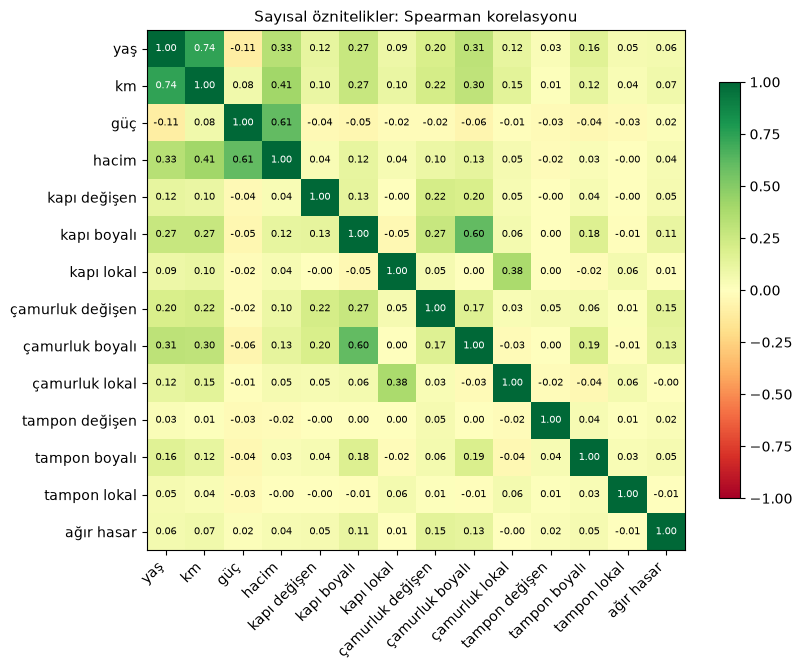

In [6]:
fig, ax = plt.subplots(figsize=(8.4, 6.8))
image = plots.heatmap(ax, spearman.rename(index=NUM_TR, columns=NUM_TR), cmap="RdYlGn", vmin=-1, vmax=1)
fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Sayısal öznitelikler: Spearman korelasyonu", fontsize=11)
fig.tight_layout()
plt.show()

Mutlak değeri 0.5'i aşan çiftler, en güçlüden:

In [7]:
HIGH_CORR = 0.5
high_pairs = pd.DataFrame([{"a": a, "b": b, "rho": spearman.loc[a, b]}
                           for a, b in itertools.combinations(data.NUM, 2) if abs(spearman.loc[a, b]) > HIGH_CORR])
high_pairs = high_pairs.sort_values("rho", key=abs, ascending=False, ignore_index=True)

high_pairs.replace({"a": NUM_TR, "b": NUM_TR}).round(3).rename(
    columns={"a": "birinci kolon", "b": "ikinci kolon", "rho": "Spearman"})

,birinci kolon,ikinci kolon,Spearman
0,yaş,km,0.736
1,güç,hacim,0.606
2,kapı boyalı,çamurluk boyalı,0.603


**Ne görüyoruz.** 0.5'i aşan çiftler beklenen bağlar: yaşlı araç çok yol yapmış, büyük motor güçlü, kapıları boyanmış
aracın çamurlukları da çoğunlukla boyalı. Yaş ve km boyalı ve değişen parça sayılarıyla da zayıf ama pozitif
ilişkili: eski araçta işlem görmüş parça daha çok. Bu bağların hedonik regresyondaki karşılığı 5.6'da VIF ile
ölçülüyor; orada kapı ve çamurluk boyası ayrı değil, toplam boyalı parça sayısı olarak giriyor.

## 2. Segment nereden geliyor

**Soru.** Site her ilanda bir segment de veriyor (`gb_segment`), ama tahmin modeli onu kullanmıyor; segmenti seriden
türetiyor (1. defter, Kurulum ve veri). Kural ilanları nasıl çözüyor ve sitenin segmenti neden alınmadı?

### 2.1 Kural ve çözüm yolları

Segment kuralı `data` modülünde üç tablodan oluşur:

- **seri eşlemesi** (`data.SEGMENT_MAP`): her seri bir segmente, ör. 3 Serisi ve A4 D.
- **performans ailesi** (`data.PERF_BASE`): M, S ve RS aileleri tek bir segmente düşmez; araç modeli adındaki rakam
  temel seriyi verir: M3 → 3 Serisi → D, RS 6 → A6 → E.
- **araç modeli adı tablosu** (`data.MODEL_SEG`): rakam kuralının yanlış sonuç verdiği iki ad, önce bunlara bakılır:
  i8 ve Z4 M spor araç (S).

`data.resolve_segment` bir ilanın segmentini ve onu çözen yolu verir; `data.add_features` segment kolonunu aynı
kuralla kurar ve çözülemeyen ilan kalırsa durur. Her yoldan kaç ilan çözülüyor?

In [8]:
PATHS = {"series_map": "seri eşlemesi", "base_class": "performans ailesi: temel seri",
         "model_table": "araç modeli adı tablosu"}   # yol kimliği -> gösterilen ad

segment_path = pd.Series([data.resolve_segment(s, m)[1] for s, m in zip(listings["series"], listings["model"])],
                         index=listings.index)
print("Seri eşlemesindeki seri:", len(data.SEGMENT_MAP))

segment_path.value_counts().rename(index=PATHS).rename_axis("çözüm yolu").rename("ilan").to_frame()

Seri eşlemesindeki seri: 18


,ilan
çözüm yolu,
seri eşlemesi,29832
performans ailesi: temel seri,137
araç modeli adı tablosu,19


Seri eşlemesi dışında çözülen ilanlar hangi serilerden ve hangi segmentlere düşüyor?

In [9]:
from_model_name = listings[segment_path != "series_map"]

from_model_name.groupby("series")["segment"].value_counts().unstack(fill_value=0).rename_axis(
    index="seri", columns="segment")

segment,C,D,E,F,S
seri,,,,,
M Serisi,8,44,29,0,1
RS,0,1,1,0,0
S,43,8,0,3,0
i Serisi,0,0,0,0,18


Birden çok segmente yayılan seriler ve 1. bölümdeki U(segment | seri):

In [10]:
segments_per_series = listings.groupby("series")["segment"].nunique()
print("Birden çok segmente düşen seri:", ", ".join(segments_per_series.index[segments_per_series > 1]))
print("U(segment | seri):", round(theils.loc["segment", "series"], 3))

Birden çok segmente düşen seri: M Serisi, RS, S
U(segment | seri): 0.997


**Ne görüyoruz.** İlanların neredeyse hepsi segmentini doğrudan serisinden alıyor. Performans aileleri birden çok
segmente yayılıyor: M Serisi'nin bir araç modeli C, bir başkası E olabiliyor. Bu yüzden segment yalnız serinin değil,
seriyle araç modeli adının birlikte fonksiyonu; U(segment | seri) tam 1 değil. Araç modeli adı tablosu i8 ve Z4 M
ilanlarını spor araç yapıyor.

### 2.2 Sitenin segmenti

Sitenin segmenti `gb_segment` kolonunda, "D Segment" gibi; ilanların bir kısmında boş. `cleaning.raw_segment` her
değeri kısa bir kimliğe (B … G) çevirir; veride hiç görülmemiş bir değer gelirse durur. Önce sitenin "G" segmenti:
bu ilanların serisi ve kasa tipi ne? Kasa tipi kısa bilgi sekmesindeki `kb_body_type`: genel bakış sekmesindeki ikizi
kasa tipini koltuk sayısıyla birleştirdiği için daha genel olan bu taraf kullanılıyor (1. defter, 4.4).

In [11]:
raw_segment = cleaning.raw_segment(listings["gb_segment"])
g_listings = listings[raw_segment == "G"]
print("Sitenin G dediği ilan:", len(g_listings))
print("Serileri:", g_listings["series"].value_counts().to_dict())

g_listings["kb_body_type"].value_counts().rename_axis("kasa tipi").rename("ilan").to_frame()

Sitenin G dediği ilan: 215
Serileri: {'2 Serisi': 215}


,ilan
kasa tipi,
MPV,214
Station wagon,1


**Ne görüyoruz.** "G" gerçek bir segment değil: bu ilanların neredeyse hepsi MPV kasalı ve hepsi tek bir seriden.
Sitenin segment kolonu burada kasa tipini segment gibi taşıyor. MPV bilgisi kasa tipi kolonunda zaten var; segment bu
yüzden seriden türetiliyor ve bu ilanlar serilerinin segmentini alıyor.

Sitenin segmenti dolu olan ilanlarda türetilen segment siteninkinden ne sıklıkla ayrılıyor, hangi yönde?

In [12]:
known = raw_segment.notna()
differs = known & (raw_segment != listings["segment"])
print(f"Sitenin segmenti dolu ilan: {known.sum()}; türetilenden farklı: {differs.sum()} "
      f"(%{100 * differs.sum() / known.sum():.2f})")

mismatch = pd.DataFrame({"raw": raw_segment[differs], "derived": listings.loc[differs, "segment"]}).value_counts()
mismatch.rename_axis(["sitenin segmenti", "türetilen segment"]).rename("ilan").to_frame()

Sitenin segmenti dolu ilan: 21723; türetilenden farklı: 404 (%1.86)


ilan
sitenin segmenti türetilen segment      
G                C                   215
E                D                    95
                 S                    61
F                E                    32
                 S                     1

**Ne görüyoruz.** Ayrılan ilanların yarısından fazlası bilinçli G düzeltmesi: sitenin G dediği ilanlar türetilen
segmentte serilerinin segmentini alıyor. Geri kalanlarda sitenin E ya da F dediği bazı ilanlar kuralda bir alt
segmente ya da spor sınıfına düşüyor. Ayrışma ilanların küçük bir kısmında: seriden türetilen segment sitenin
bilgisiyle büyük ölçüde örtüşüyor ve bozuk G etiketini düzeltiyor.

### 2.3 Seri ve segmente göre fiyat

Her (seri, segment) hücresinde medyan fiyat (milyon ₺). Boş hücre o seride o segmentten ilan olmadığını, nokta
hücrenin tek bir ilandan oluştuğunu gösterir.

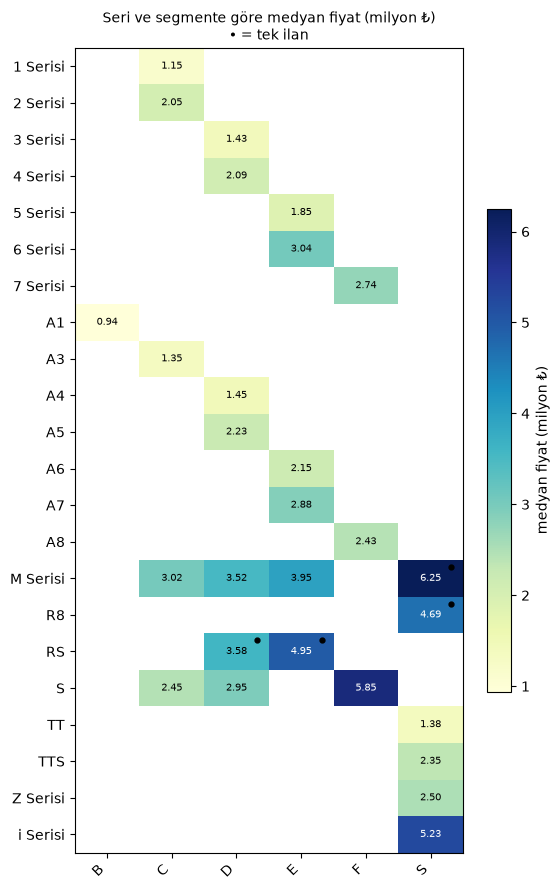

In [13]:
cells = listings.groupby(["series", "segment"])["price"].agg(["median", "size"])
median_table = cells["median"].unstack() / 1e6
single = (cells["size"].unstack() == 1).to_numpy()

fig, ax = plt.subplots(figsize=(5.8, 9))
image = plots.heatmap(ax, median_table, cmap="YlGnBu")
rows, columns = np.nonzero(single)
ax.plot(columns + 0.32, rows - 0.3, "o", ms=3.5, color="black")
fig.colorbar(image, ax=ax, shrink=0.6, label="medyan fiyat (milyon ₺)")
ax.set_title("Seri ve segmente göre medyan fiyat (milyon ₺)\n• = tek ilan", fontsize=10)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Seriler çoğunlukla tek bir segmentte; yalnız performans aileleri birden çok hücreye yayılıyor ve
B dışında her segmentte en pahalı hücre bir performans ailesinin. Aynı segmentin içinde seriler arasında belirgin
fiyat farkı var: segment fiyatın yalnız kaba bir göstergesi. Performans ailelerinin bazı hücreleri tek bir ilan; o
hücrenin medyanı bir ilanın fiyatı.

## 3. Hedef: fiyat

**Soru.** İlan fiyatı nasıl dağılıyor ve tahmin modeli neden fiyatın kendisini değil log fiyatı hedef alıyor? Önce
fiyatın yüzdelikleri:

In [14]:
price = listings["price"]
price.quantile([0.1, 0.5, 0.9]).rename({0.1: "%10", 0.5: "%50 (medyan)", 0.9: "%90"}).astype(int).rename_axis(
    "yüzdelik").rename("fiyat (₺)").to_frame().T

yüzdelik,%10,%50 (medyan),%90
fiyat (₺),845000,1545000,3425000


Çarpıklık dağılımın ne kadar tek yana uzandığını ölçer: 0 simetrik, pozitif değer sağa (pahalı uca) uzanan bir
kuyruk demek. Fiyatın ve log fiyatın çarpıklığı:

In [15]:
skewness = pd.Series({"price": stats.skew(price), "log_price": stats.skew(np.log1p(price))})
skewness.round(2).rename({"price": "fiyat", "log_price": "log fiyat"}).rename_axis("hedef").rename(
    "çarpıklık").to_frame()

,çarpıklık
hedef,
fiyat,1.62
log fiyat,0.28


Fiyat histogramı: sıfırdan en yüksek fiyata kadar 250 bin ₺ genişliğinde kovalar; kesikli çizgi medyan.

Kovalara düşen ilan: 29988 / 29988


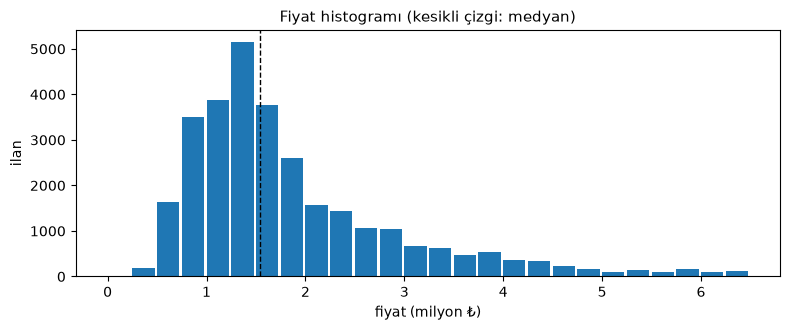

In [16]:
BIN = 250_000
edges = np.arange(0, price.max() + BIN, BIN)
counts, _ = np.histogram(price, bins=edges)
print("Kovalara düşen ilan:", counts.sum(), "/", len(price))

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(edges[:-1] / 1e6, counts, width=0.9 * BIN / 1e6, align="edge")
ax.axvline(price.median() / 1e6, color="black", ls="--", lw=1)
ax.set(xlabel="fiyat (milyon ₺)", ylabel="ilan")
ax.set_title("Fiyat histogramı (kesikli çizgi: medyan)", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Ham fiyat sağa çarpık: ilanların çoğu ucuz ve orta kovalarda, pahalı uç uzun ve ince bir kuyruk.
Son kova toplama tavanında bitiyor (1. defter, 1.4); tavanın üstünde ilan yok. Log dönüşümü dağılımı simetriğe çok
yaklaştırıyor. Tahmin modeli log fiyat üzerinde eğitilir (3. defter): log ölçekte fark göreli (yüzde) farka karşılık
gelir, yani ucuz ve pahalı araçta aynı yüzde hata aynı ağırlığı taşır. Bu bir modelleme kararı, piyasa bulgusu değil.
Bu defterdeki regresyonlar da log fiyat üzerinde.

## 4. Piyasa

**Soru.** Ham fiyat, yani başka hiçbir şey sabitlenmeden, segmente, kasa tipine, yaşa, kilometreye ve markaya göre
nasıl değişiyor? Bu tablolar düzeltilmemiş: bir grubun fiyatı o gruptaki araçların karışımını da taşır (ör. yaşlı
araçlar daha çok kilometre yapmış). Öteki özellikler sabitken karşılaştırma 5. bölümde.

### 4.1 Segment ve kasa tipi

Segment başına medyan fiyat ve ilan sayısı, en ucuzdan:

In [17]:
by_segment = listings.groupby("segment")["price"].agg(median="median", n="size").sort_values("median")

by_segment.round().astype(int).rename_axis("segment").rename(columns={"median": "medyan fiyat (₺)", "n": "ilan"})

,medyan fiyat (₺),ilan
segment,,
B,939500,127
C,1310000,9190
D,1525000,12357
E,1939875,7870
S,2490000,119
F,2675000,325


Kasa tipi başına aynı tablo, en az 80 ilanı olan kasa tipleri. Kasa tipi kısa bilgi sekmesindeki daha genel kolon
(`kb_body_type`, 2.2). Kasa tipi verilmemiş ilanlarda kasa tipi araç modeli adından çıkarılmıyor, çünkü aynı ad
farklı kasa tiplerinde satılıyor; bu ilanlar ayrı bir grup (`missing`).

In [18]:
MIN_BODY_N = 80
by_body = listings.groupby("kb_body_type")["price"].agg(median="median", n="size")
by_body = by_body[by_body["n"] >= MIN_BODY_N].sort_values("median")

by_body.round().astype(int).rename(index={"missing": "(verilmemiş)"}).rename_axis("kasa tipi").rename(
    columns={"median": "medyan fiyat (₺)", "n": "ilan"})

,medyan fiyat (₺),ilan
kasa tipi,,
Hatchback/3,830000,844
Hatchback/5,1280000,5829
MPV,1415000,227
Sedan,1600000,20355
Station wagon,1645000,485
Coupe,2034750,1856
(verilmemiş),2575000,291


Grafik kasa tipi verilmemiş grubu çizmiyor; o grubu ve daha az ilanlı kasa tiplerini başlıkta sayıyor.

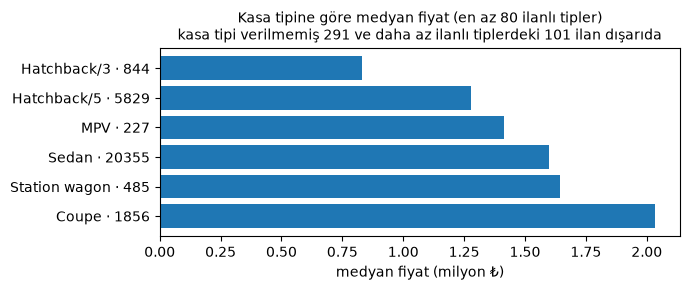

In [19]:
shown_bodies = by_body.drop("missing")
n_unknown_body = (listings["kb_body_type"] == "missing").sum()
n_small_bodies = len(listings) - n_unknown_body - shown_bodies["n"].sum()

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh([f"{body} · {n}" for body, n in shown_bodies["n"].items()], shown_bodies["median"] / 1e6)
ax.invert_yaxis()
ax.set_xlabel("medyan fiyat (milyon ₺)")
ax.set_title(f"Kasa tipine göre medyan fiyat (en az {MIN_BODY_N} ilanlı tipler)\nkasa tipi verilmemiş "
             f"{n_unknown_body} ve daha az ilanlı tiplerdeki {n_small_bodies} ilan dışarıda", fontsize=10)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Segment sırası beklenen sıra: B en ucuz, F en pahalı, spor araçlar (S) F'nin hemen altında. Kasa
tipinde 3 kapılı hatchback en ucuz, coupe en pahalı. Kasa tipi verilmemiş ilanların medyanı yüksek, ama bu bir kasa
tipi değil, farklı araç modellerinden gelen karışık bir grup; grafikte bu yüzden çizilmiyor.

### 4.2 Yaş ve kilometre

Yaş başına (en çok 25 yaş, en az 10 ilanlı yaşlar) ve 25 bin km'lik kilometre kovası başına (400 bin km'nin altı)
medyan ve ortalama fiyat. Ortalama pahalı ilanlardan etkilenir, medyan tipik ilanı gösterir; aradaki açıklık
fiyatın çarpıklığından.

In [20]:
MAX_AGE, MIN_AGE_N = 25, 10
by_age = listings[listings["vehicle_age"] <= MAX_AGE].groupby("vehicle_age")["price"].agg(
    median="median", n="size", mean="mean")
by_age = by_age[by_age["n"] >= MIN_AGE_N]

KM_BIN, KM_LIMIT = 25_000, 400_000
below_limit = listings[listings["gb_mileage"] < KM_LIMIT]
by_km = below_limit.groupby(below_limit["gb_mileage"] // KM_BIN * KM_BIN)["price"].agg(
    median="median", n="size", mean="mean")

print(f"Gösterilen yaşlar: {by_age.index.min()}-{by_age.index.max()} ({by_age['n'].sum()} ilan)")
print(f"{KM_LIMIT // 1000} bin km ve üstü, grafiğin dışında:", (listings["gb_mileage"] >= KM_LIMIT).sum(), "ilan")

Gösterilen yaşlar: 1-21 (29986 ilan)
400 bin km ve üstü, grafiğin dışında: 653 ilan


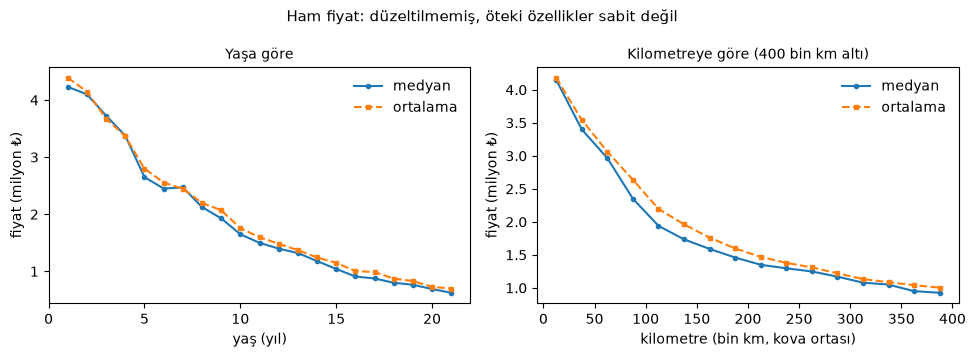

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, table, x, label in [(axes[0], by_age, by_age.index, "yaş (yıl)"),
                            (axes[1], by_km, (by_km.index + KM_BIN / 2) / 1000, "kilometre (bin km, kova ortası)")]:
    ax.plot(x, table["median"] / 1e6, "o-", ms=3, label="medyan")
    ax.plot(x, table["mean"] / 1e6, "s--", ms=3, label="ortalama")
    ax.set(xlabel=label, ylabel="fiyat (milyon ₺)")
    ax.legend(frameon=False)
axes[0].set_xticks(range(0, int(by_age.index.max()) + 1, 5))
axes[0].set_title("Yaşa göre", fontsize=10)
axes[1].set_title(f"Kilometreye göre ({KM_LIMIT // 1000} bin km altı)", fontsize=10)
fig.suptitle("Ham fiyat: düzeltilmemiş, öteki özellikler sabit değil", fontsize=11)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Ham fiyat yaşla ve kilometreyle düzenli düşüyor. Ortalama çoğu noktada medyanın üstünde: her
grubun içinde pahalı bir kuyruk var. Bu eğriler düzeltilmemiş: yaşlı araç hem daha çok kilometre yapmış hem başka
araç modellerinden. Yaşın ve kilometrenin, öteki özellikler sabitken fiyatla ilişkisi 5. bölümde.

### 4.3 BMW ve Audi

İki markanın ilan sayısı, medyan ve ortalama fiyatı. Farkın büyüklüğü için Cliff's delta: rastgele bir BMW ilanının
rastgele bir Audi ilanından pahalı olma olasılığı eksi ucuz olma olasılığı. −1 ile 1 arasında; 0 iki dağılımın iç
içe olduğunu, ±1 tamamen ayrıldığını söyler. `market.cliffs_delta` bunu bütün ilan çiftleri üzerinden, örnekleme
yapmadan hesaplar. Anlamlılık testi (ör. Mann–Whitney) yapılmadı: bu büyüklükte iki grupta çok küçük bir fark da
"anlamlı" çıkar ve farkın büyüklüğü hakkında bir şey söylemez.

In [22]:
by_brand = listings.groupby("brand")["price"].agg(n="size", median="median", mean="mean").reindex(["bmw", "audi"])
delta = market.cliffs_delta(listings.loc[listings["brand"] == "bmw", "price"],
                            listings.loc[listings["brand"] == "audi", "price"])
print("Cliff's delta (BMW ile Audi):", round(delta, 3))

by_brand.round().astype(int).rename(index={"bmw": "BMW", "audi": "Audi"}).rename_axis("marka").rename(
    columns={"n": "ilan", "median": "medyan fiyat (₺)", "mean": "ortalama fiyat (₺)"})

Cliff's delta (BMW ile Audi): 0.066


,ilan,medyan fiyat (₺),ortalama fiyat (₺)
marka,,,
BMW,17896,1575000,1910680
Audi,12092,1475000,1822023


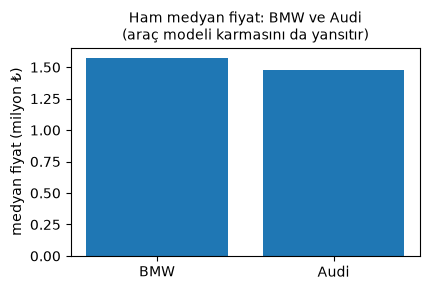

In [23]:
fig, ax = plt.subplots(figsize=(4.4, 3))
ax.bar(["BMW", "Audi"], by_brand["median"] / 1e6)
ax.set_ylabel("medyan fiyat (milyon ₺)")
ax.set_title("Ham medyan fiyat: BMW ve Audi\n(araç modeli karmasını da yansıtır)", fontsize=10)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** BMW'nin ham medyanı Audi'ninkinden biraz yüksek, ama delta sıfıra çok yakın: iki markanın fiyat
dağılımları neredeyse tamamen iç içe. Ham fark iki markanın araç modeli karmasını da yansıtıyor; 1. bölümde marka
araç modelinden ve seriden tamamen okunuyordu. Markanın tahmin modeline katkısı 3. defterde ölçülüyor.

### 4.4 Doğal kümeler var mı

Piyasayı segment ve kasa tipi gibi açık kolonlarla okuyoruz. Bunların yerine geçebilecek doğal kümeler var mı? 14
sayısal öznitelikte boş değerler kolon medyanıyla dolduruluyor, her kolon standartlaştırılıyor (ortalama 0,
standart sapma 1) ve KMeans k = 2 … 8 küme için kuruluyor. Her k için silhouette skoru: −1 ile 1 arasında; 1'e yakın
değer kümelerin iyi ayrıldığını, 0'a yakın değer iç içe olduğunu söyler. Kümeler bütün ilanlarda kuruluyor, skor
rastgele seçilmiş 3.000 ilanda hesaplanıyor (bütün ilanlarda hesaplamak çok yavaş).

In [24]:
SEED, K_RANGE, SILHOUETTE_SAMPLE = 42, range(2, 9), 3000
numeric = listings[data.NUM].fillna(listings[data.NUM].median())
scaled = StandardScaler().fit_transform(numeric)
sample = np.random.default_rng(SEED).choice(len(scaled), SILHOUETTE_SAMPLE, replace=False)

silhouette = {}
for k in K_RANGE:
    labels = KMeans(k, random_state=SEED, n_init=10).fit(scaled).labels_
    silhouette[k] = silhouette_score(scaled[sample], labels[sample])

pd.Series(silhouette).round(3).rename_axis("k").rename("silhouette").to_frame().T

k,2,3,4,5,6,7,8
silhouette,0.242,0.188,0.193,0.194,0.239,0.231,0.224


**Ne görüyoruz.** Silhouette denenen bütün k değerlerinde düşük, 0.25'in altında: bu ölçekte belirgin bir küme yapısı
yok. Kümeler bu yüzden analizde kullanılmıyor; piyasa segment ve kasa tipi gibi açık özniteliklerle okunuyor.

## 5. Hedonik regresyon

**Soru.** İki soru. Birincisi: log fiyatın ne kadarını yalnız aracın kimliği, ne kadarını yalnız durumu, ne kadarını
ikisi birlikte açıklıyor? İkincisi: aracın kimliği sabitken durumu ve motoru fiyatla nasıl ilişkili, ve her ilişki
kimlik sabitlenince nasıl değişiyor?

Yöntem hedonik regresyon: log fiyatı aracın özelliklerine bağlayan doğrusal regresyon (en küçük kareler, OLS).
Burada fiyat tahmini için değil, ikinci soru için kuruluyor; fiyatı tahmin etmek tahmin modelinin işi (3. defter).
Katsayılar nedensel etki değil, kontrollü ilişkidir: ör. boyalı parçanın katsayısı boyamanın fiyatı düşürdüğünü
değil, boyalı parçalı ilanların benzerlerinden o kadar ucuz ilan edildiğini söyler. Regresyonda tarama (dönem) etkisi
yok: dört taramanın ilanları birlikte kestiriliyor.

### 5.1 Regresyon tablosu

Regresyonun kolonları:

- `log_price`: log(1 + fiyat), hedef.
- `age`: yaş (yıl); `km100k`: kilometre, 100 bin km cinsinden.
- `heavy_damage`: ağır hasar kaydı (1 var, 0 yok ya da belirtilmemiş).
- `painted`, `changed`: boyalı ve değişen parça sayısı, 13 parçanın tamamında: veritabanının `count_painted` ve
  `count_changed` sayaçları. Tahmin modelinin kapı, çamurluk ve tampon ayrımı yerine toplam sayı.
- `hp100`: motor gücü / 100; `litre`: motor hacmi / 1000. İkisi de 1. defterin motor kuralıyla (güç aralığın orta
  noktası, hacim üst sınırı).

Kimlik kolonları (`segment`, `brand`, `kb_fuel`, `kb_transmission`, `model`) ilan tablosunda olduğu gibi kalıyor.

In [25]:
reg_table = listings.copy()
reg_table["log_price"] = np.log1p(reg_table["price"])
reg_table["age"] = reg_table["vehicle_age"]
reg_table["km100k"] = reg_table["gb_mileage"] / 1e5
reg_table["heavy_damage"] = reg_table["is_heavy_damaged"]
reg_table["painted"] = reg_table["count_painted"]
reg_table["changed"] = reg_table["count_changed"]
reg_table["hp100"] = reg_table["power_hp_val"] / 100
reg_table["litre"] = reg_table["engine_cc_val"] / 1000

OLS boş değerle çalışmaz. Motor gücü ya da hacmi boş olan ilanlar (1. defter, 2.2: değeri olmayan ilanlar) bu yüzden
regresyona giremez. Kaç ilan, hangi yüzden? İkisi birden boş olan ilan toplamda bir kez sayılır.

In [26]:
has_hp, has_cc = listings["power_hp_val"].notna(), listings["engine_cc_val"].notna()
dropped = pd.Series({"hp": (~has_hp).sum(), "cc": (~has_cc).sum(), "both": (~has_hp & ~has_cc).sum(),
                     "total": (~(has_hp & has_cc)).sum()})

dropped.rename({"hp": "gücü boş", "cc": "hacmi boş", "both": "ikisi de boş", "total": "regresyona girmeyen"}).to_frame(
    "ilan")

,ilan
gücü boş,426
hacmi boş,356
ikisi de boş,348
regresyona girmeyen,434


Kalan ilanlarda yaş ve kilometre **medyan araca** ortalanır: medyan yaş ve medyan kilometre çıkarılır. Kare ve
etkileşim terimleri varken yaşın ve kilometrenin katsayısı böylece medyan araçtaki marjinal etki olur. Ortalamak
tahminleri ve R²'yi değiştirmez, yalnız katsayıların okunduğu noktayı belirler.

In [27]:
reg_table = reg_table[has_hp & has_cc]
age_center, km_center = reg_table["age"].median(), reg_table["km100k"].median()
reg_table["age"] = reg_table["age"] - age_center
reg_table["km100k"] = reg_table["km100k"] - km_center

print("Regresyondaki ilan:", len(reg_table), "| araç modeli:", reg_table["model"].nunique())
print(f"Medyan araç: {age_center:g} yaş, {km_center * 1e5:,.0f} km")

Regresyondaki ilan: 29554 | araç modeli: 735
Medyan araç: 11 yaş, 181,000 km


### 5.2 Formüller

Regresyonlar patsy formülüyle yazılıyor: `~` işaretinin solu hedef, sağı açıklayıcılar. `I(age ** 2)` yaşın karesi,
`age:km100k` yaş ile kilometrenin çarpımı (etkileşim: yaşın fiyatla ilişkisi kilometreye göre değişebilir). `C(...)`
kategorik bir kolonun her değeri için bir kukla (0/1) kolon; ilk değer referans. Formüller üç parçadan kuruluyor:

- **durum** (`CONDITION`): yaş, km, kareleri ve etkileşimi, ağır hasar, boyalı ve değişen parça.
- **motor** (`ENGINE`): güç ve hacim.
- **kimlik kontrolleri** (`CONTROLS`): segment, marka, yakıt ve vites kuklaları. Daha ince kimlik araç modelinin adı
  (`C(model)`): her araç modeli için bir kukla.

In [28]:
CONDITION = "age + I(age ** 2) + km100k + I(km100k ** 2) + age:km100k + heavy_damage + painted + changed"
ENGINE = "hp100 + litre"
CONTROLS = "C(segment) + C(brand) + C(kb_fuel) + C(kb_transmission)"
TERMS = f"{CONDITION} + {ENGINE}"

TERM_TR = {"age": "yaş", "I(age ** 2)": "yaş²", "km100k": "km (100 bin)", "I(km100k ** 2)": "km²",
           "age:km100k": "yaş×km", "heavy_damage": "ağır hasar", "painted": "boyalı parça",
           "changed": "değişen parça", "hp100": "+100 hp", "litre": "+1 litre"}   # terim -> gösterilen ad
TERM_NAMES = list(TERM_TR)

### 5.3 Fiyatı ne açıklıyor

Aynı ilanlarda altı regresyon: yalnız kimlik (iki düzeyde), yalnız durum, durum ve motor, sonra ikisi birlikte. Her
biri için R² (log fiyatın açıklanan payı) iki kez: örneklem içi, yani regresyonun kurulduğu ilanlarda, ve kat dışı.
Kat dışı için ilanlar `folds.make_folds` ile beş kata bölünüyor (karıştırılmış, tohum 42; tahmin modelinin kat dışı
sayıları da aynı fonksiyonla, 3. defter). `hedonic.oof_predictions` her katın ilanlarını öteki dört katta kurulan
regresyonla tahmin eder; eğitim katlarında hiç görülmeyen bir araç modelinin kuklası sıfır alır, yani o ilan kalan
kolonlardan tahmin edilir. İki R² de log fiyatın genel ortalaması etrafındaki kareler toplamına göre.

In [29]:
LADDER = {
    "identity_segment": CONTROLS,
    "identity_model": "C(model)",
    "condition": CONDITION,
    "condition_engine": TERMS,
    "segment_control": f"{TERMS} + {CONTROLS}",
    "model_control": f"{TERMS} + {CONTROLS} + C(model)",
}
LADDER_TR = {"identity_segment": "yalnız segment, marka, yakıt, vites", "identity_model": "yalnız araç modelinin adı",
             "condition": "yalnız durum", "condition_engine": "durum + motor",
             "segment_control": "durum + motor + segment, marka, yakıt, vites (segment kontrolü)",
             "model_control": "segment kontrolü + araç modelinin adı (araç modeli kontrolü)"}   # yalnız gösterim için

In [30]:
y = reg_table["log_price"].to_numpy()
total_ss = ((y - y.mean()) ** 2).sum()
cv_folds = folds.make_folds(len(reg_table))

ladder = {}
for name, rhs in LADDER.items():
    X = patsy.dmatrix(rhs, reg_table, return_type="dataframe").to_numpy()
    in_sample = X @ np.linalg.lstsq(X, y, rcond=None)[0]
    out_of_fold = hedonic.oof_predictions(X, y, cv_folds)
    ladder[name] = {"n_columns": X.shape[1], "r2_in_sample": 1 - ((y - in_sample) ** 2).sum() / total_ss,
                    "r2_out_of_fold": 1 - ((y - out_of_fold) ** 2).sum() / total_ss}
ladder = pd.DataFrame.from_dict(ladder, orient="index")

ladder.round(4).rename(index=LADDER_TR, columns={"n_columns": "kolon (sabit dahil)", "r2_in_sample": "R² örneklem içi",
                                                 "r2_out_of_fold": "R² kat dışı"}).rename_axis("regresyon")

,kolon (sabit dahil),R² örneklem içi,R² kat dışı
regresyon,,,
"yalnız segment, marka, yakıt, vites",12,0.3788,0.3785
yalnız araç modelinin adı,735,0.8475,0.8220
yalnız durum,9,0.7311,0.7309
durum + motor,11,0.8720,0.8719
"durum + motor + segment, marka, yakıt, vites (segment kontrolü)",22,0.9312,0.9310
segment kontrolü + araç modelinin adı (araç modeli kontrolü),756,0.9648,0.9610


Kat dışı R²'yi üç parçaya ayırıyoruz. **Yalnız durumun kattığı**: araç modeli kontrolü eksi yalnız araç modelinin
adı. **Yalnız kimliğin kattığı**: araç modeli kontrolü eksi yalnız durum (motor burada kimlik tarafında sayılıyor).
**Ortak**: geri kalanı; durum ve kimlik birbirinden bağımsız değil, bu kısmı ikisinden biri tek başına da açıklıyor.

In [31]:
oof_r2 = ladder["r2_out_of_fold"]
parts = pd.Series({"condition_only": oof_r2["model_control"] - oof_r2["identity_model"],
                   "identity_only": oof_r2["model_control"] - oof_r2["condition"]})
parts["shared"] = oof_r2["model_control"] - parts.sum()

parts.round(4).rename({"condition_only": "yalnız durumun kattığı", "identity_only": "yalnız kimliğin kattığı",
                       "shared": "ortak"}).rename_axis("parça").to_frame("R² (kat dışı)")

,R² (kat dışı)
parça,
yalnız durumun kattığı,0.1390
yalnız kimliğin kattığı,0.2301
ortak,0.5919


**Ne görüyoruz.** Yalnız segment, marka, yakıt ve vites log fiyatın küçük bir kısmını açıklıyor. Yalnız durum çok
daha fazlasını, yalnız araç modelinin adı ondan da fazlasını açıklıyor. Durum ve motor birlikte kaba kimliğin çok
üstünde; kimlik ve durum birlikte en yüksek. Üç parçanın en büyüğü ortak kısım: fiyat farklarının çoğunu durum da
kimlik de tek başına açıklayabiliyor, çünkü ikisi birlikte değişiyor. Örneklem içi R² kat dışından en çok yalnız araç
modelinin adında yüksek: az ilanlı araç modellerinde kukla kendi ilanlarına uyuyor, görmediği ilanda o kadar
tutmuyor; okunan sayı bu yüzden kat dışı R².

### 5.4 Kimlik sabitken etkiler: üç sütun

Aynı on terim üç regresyonda:

- **kimlik yok**: yalnız durum ve motor terimleri.
- **segment kontrolü**: segment, marka, yakıt ve vites kuklaları eklenir.
- **araç modeli kontrolü**: bunlara araç modelinin adı da eklenir; her etki aynı araç modelinin ilanları arasında
  ölçülür.

`hedonic.fit_clustered` regresyonu kurar. Araç modeli kontrolünde araç modelinin kuklaları tasarıma açıkça konmaz:
log fiyat ve her kolon kendi araç modelinin ortalamasından çıkarılır (grup içi dönüşüm). Bu, kuklalarla aynı
katsayıları verir ve tasarımı tam ranklı tutar; araç modelinin içinde sabit kalan kolonlar (sabit terim, marka, çoğu
segment kuklası) düşer. Fonksiyon on terimden biri düşerse ya da tabloda boş değer varsa durur.

Standart hatalar **araç modeline göre kümeli**: aynı araç modelinin ilanları birbirinden bağımsız değil (aynı katalog
değerleri, benzer fiyatlama), her araç modeli bir küme. %95 aralıklar küme sayısı eksi bir serbestlik dereceli t
dağılımından. Fonksiyon R²'yi de verir; araç modeli kontrolünde bu, kuklalı regresyonun R²'si.

In [32]:
COLUMNS = {"no_identity": (f"log_price ~ {TERMS}", None),
           "segment_control": (f"log_price ~ {TERMS} + {CONTROLS}", None),
           "model_control": (f"log_price ~ {TERMS} + {CONTROLS}", "model")}   # sütun -> (formül, emilen grup)
COLUMNS_TR = {"no_identity": "kimlik yok", "segment_control": "segment kontrolü",
              "model_control": "araç modeli kontrolü"}

fits, r2 = {}, {}
for name, (formula, absorb) in COLUMNS.items():
    fits[name], r2[name] = hedonic.fit_clustered(reg_table, formula, cluster="model", absorb=absorb, tracked=TERM_NAMES)

pd.Series(r2).round(4).rename(COLUMNS_TR).rename_axis("sütun").to_frame("R² (örneklem içi)")

,R² (örneklem içi)
sütun,
kimlik yok,0.8720
segment kontrolü,0.9312
araç modeli kontrolü,0.9648


`hedonic.coefficient_table` her terimin katsayısını, kümeli standart hatasını ve %95 aralığını verir; bunları fiyata
yüzde etkiye çevirir: etki = 100 · (e^katsayı − 1). Tabloda her sütun için etki ve aralığın alt ve üst sınırı (%).

In [33]:
coefs = {name: hedonic.coefficient_table(fit, TERM_NAMES) for name, fit in fits.items()}
effects = pd.concat({COLUMNS_TR[name]: table[["pct", "pct_lo", "pct_hi"]] for name, table in coefs.items()}, axis=1)

effects.round(2).rename(index=TERM_TR, columns={"pct": "etki %", "pct_lo": "alt", "pct_hi": "üst"}).rename_axis(
    "terim")

kimlik yok               segment kontrolü                \
                  etki %    alt    üst           etki %    alt    üst   
terim                                                                   
yaş                -7.04  -7.62  -6.46            -6.64  -6.92  -6.37   
yaş²                0.03  -0.05   0.11             0.08   0.04   0.13   
km (100 bin)      -10.16 -11.88  -8.41           -15.11 -15.81 -14.40   
km²                 1.15   0.58   1.71             1.56   1.08   2.05   
yaş×km             -0.39  -0.73  -0.05            -0.62  -0.89  -0.35   
ağır hasar        -12.83 -13.84 -11.81           -11.60 -12.51 -10.68   
boyalı parça       -1.21  -1.37  -1.06            -1.05  -1.17  -0.92   
değişen parça      -3.53  -3.84  -3.22            -3.06  -3.33  -2.79   
+100 hp            50.15  39.36  61.78            19.86  13.89  26.15   
+1 litre           11.66   1.72  22.57             7.49   0.71  14.73   

              araç modeli kontrolü                
                            etki %    alt    üst  
terim                                             
yaş                          -5.80  -6.33  -5.27  
yaş²                          0.03  -0.03   0.08  
km (100 bin)                -14.83 -15.31 -14.34  
km²                           1.67   1.34   2.01  
yaş×km                       -0.33  -0.56  -0.10  
ağır hasar                  -12.46 -13.25 -11.67  
boyalı parça                 -0.98  -1.09  -0.88  
değişen parça                -3.12  -3.35  -2.88  
+100 hp                      19.30   6.90  33.12  
+1 litre                      5.97  -0.92  13.35

Okuma: yaş satırı medyan araçta yaş bir yıl artınca, km satırı kilometre 100 bin km artınca fiyattaki değişim. Kare
ve etkileşim terimleri (yaş², km², yaş×km) tek başına okunmaz; eğrinin bükülmesini taşır. Ağır hasar satırı kaydın
olup olmaması, boyalı ve değişen parça satırları her ek parça; +100 hp ve +1 litre satırları öteki motor terimi
sabitken.

Kimlik sabitlenince hangi terimler belirgin değişiyor? Kimliksiz sütunun aralığının, iki kontrollü sütunun
hiçbirinin aralığıyla örtüşmediği terimler:

In [34]:
no_identity = coefs["no_identity"]
apart = pd.Series(True, index=TERM_NAMES)
for name in ["segment_control", "model_control"]:
    other = coefs[name]
    apart &= (no_identity["pct_hi"] < other["pct_lo"]) | (other["pct_hi"] < no_identity["pct_lo"])

print(", ".join(TERM_TR[term] for term in TERM_NAMES if apart[term]))

km (100 bin), +100 hp


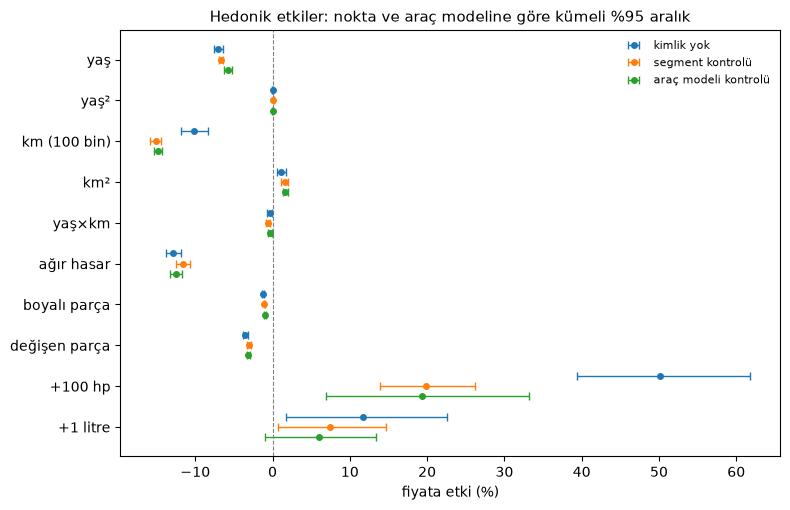

In [35]:
fig, ax = plt.subplots(figsize=(8, 5.2))
positions = np.arange(len(TERM_NAMES))
for i, (name, table) in enumerate(coefs.items()):
    errors = [table["pct"] - table["pct_lo"], table["pct_hi"] - table["pct"]]
    ax.errorbar(table["pct"], positions + (i - 1) * 0.25, xerr=errors, fmt="o", ms=4, capsize=3, lw=1,
                label=COLUMNS_TR[name])
ax.axvline(0, color="grey", ls="--", lw=0.8)
ax.set_yticks(positions, [TERM_TR[term] for term in TERM_NAMES])
ax.invert_yaxis()
ax.set_xlabel("fiyata etki (%)")
ax.set_title("Hedonik etkiler: nokta ve araç modeline göre kümeli %95 aralık", fontsize=11)
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
plt.show()

**Ne görüyoruz.** Yaş, km, ağır hasar, boyalı ve değişen parça üç sütunda da fiyatla eksi yönde ilişkili ve
aralıkları dar. Kimlik sabitlenince en belirgin değişen iki terim km ve +100 hp. **Km** kimlik olmadan daha zayıf
görünüyor: yaşı, hasarı ve motoru aynı ilanlar arasında km'si yüksek olanlar ortalamada fiyatı daha yüksek araç
modellerinden; kimliksiz katsayı bunu da taşıdığı için km'nin fiyatla ilişkisini küçük gösteriyor. **+100 hp** ise
kimlik olmadan çok daha büyük: log ölçekte kimliksiz etkinin yarıdan fazlası segment, marka, yakıt ve vites girince
gidiyor; büyük kısmı motorun kendisi değil, aracın sınıfı. Kimliksiz sütunla öteki ikisi arasında terim başına bir
fark testi yok; bu iki gözlem aralıkların örtüşmemesine dayanıyor. Motor terimlerinin aralıkları araç modeli
kontrolünde segment kontrolündekinden geniş: araç modelinin adı motoru büyük ölçüde belirlediği için orada güç ve
hacim yalnız aynı araç modelinin ilanları arasındaki farktan ölçülüyor (5.9).

### 5.5 Güven aralıkları ve sütunların farkı

Kümeli standart hatanın ikinci gerekçesi: hata varyansı ilandan ilana eşit değilse sıradan standart hatalar
yanlıştır. Breusch–Pagan testi bunu segment kontrolü sütununun artıklarında sınar; küçük p, eşit varyansın
reddedilmesi demek.

In [36]:
bp_p = het_breuschpagan(fits["segment_control"].resid, fits["segment_control"].model.exog)[1]
print("Breusch-Pagan p:", f"{bp_p:.3g}")

Breusch-Pagan p: 0


Segment kontrolü ile araç modeli kontrolü sütunlarının farkı örnekleme hatasından büyük mü? İki regresyon aynı
ilanlarda kurulduğu için farkları, bağımsız iki tahminin farkı gibi sınanamaz. `hedonic.difference_test` her terim
için farkın standart hatasını iki regresyonun ilan başına etkilerinin (influence) farkından, yine araç modeline göre
kümeli olarak hesaplar ve %5 düzeyinde sınar. Fark log ölçekte: segment kontrolü eksi araç modeli kontrolü.

In [37]:
difference = hedonic.difference_test(fits["segment_control"], fits["model_control"], reg_table["model"], TERM_NAMES)
print("Küme (araç modeli):", reg_table["model"].nunique())

shown = difference.round({"diff": 5, "se": 5, "t": 2})
shown["significant"] = shown["significant"].map({True: "evet", False: "hayır"})
shown.rename(index=TERM_TR, columns={"diff": "fark (log)", "se": "standart hata", "significant": "anlamlı (%5)"}
             ).rename_axis("terim")

Küme (araç modeli): 735


,fark (log),standart hata,t,anlamlı (%5)
terim,,,,
yaş,-0.00896,0.00266,-3.37,evet
yaş²,0.00056,0.00029,1.90,hayır
km (100 bin),-0.00330,0.00334,-0.99,hayır
km²,-0.00110,0.00148,-0.75,hayır
yaş×km,-0.00290,0.00086,-3.37,evet
ağır hasar,0.00979,0.00346,2.83,evet
boyalı parça,-0.00063,0.00032,-2.00,evet
değişen parça,0.00054,0.00073,0.74,hayır
+100 hp,0.00474,0.05645,0.08,hayır


Duyarlılık: standart hatalar seriye göre kümelenince hangi terimlerin aralığı sıfırı içeriyor? Seri az sayıda ve
büyüklükleri çok dengesiz olduğu için bu yalnız karşılaştırma için; araç modeline göre kümeyle yan yana. Tablonun
her hücresi, aralığı sıfırı içeren terimler.

In [38]:
zero_terms = {}
for name in ["segment_control", "model_control"]:
    formula, absorb = COLUMNS[name]
    by_series, _ = hedonic.fit_clustered(reg_table, formula, cluster="series", absorb=absorb, tracked=TERM_NAMES)
    for cluster, fit in [("model", fits[name]), ("series", by_series)]:
        contains_zero = hedonic.coefficient_table(fit, TERM_NAMES)["contains_zero"]
        zero_terms[name, cluster] = ", ".join(TERM_TR[term] for term in TERM_NAMES if contains_zero[term]) or "yok"
print("Küme (seri):", reg_table["series"].nunique())

pd.Series(zero_terms).unstack().loc[["segment_control", "model_control"]].rename(index=COLUMNS_TR, columns={
    "model": "araç modeline göre küme", "series": "seriye göre küme"}).rename_axis(index="sütun", columns=None)

Küme (seri): 22


,araç modeline göre küme,seriye göre küme
sütun,,
segment kontrolü,yok,+1 litre
araç modeli kontrolü,"yaş², +1 litre","yaş², yaş×km, +1 litre"


**Ne görüyoruz.** Breusch–Pagan eşit varyansı açıkça reddediyor; kümeli standart hata bu yüzden de gerekli. Segment
ve araç modeli kontrolünün farkı yaş, yaş×km, ağır hasar ve boyalı parçada örnekleme hatasından büyük; km, değişen
parça ve motor terimlerinde değil. Anlamlı farklar da etki tablosunda küçük: araç modelini sabitlemek bu terimleri
biraz kaydırıyor, yönlerini değiştirmiyor. Seriye göre kümelenince aralığı sıfırı içeren terimler artıyor: aynı
serinin araç modelleri de birbirinden bağımsız değil, bu terimlerin anlamlılığı kümelemenin seçimine bağlı.

### 5.6 Çoklu bağlantı

VIF (varyans şişme çarpanı) bir terimin tasarımdaki öteki kolonlardan ne kadar okunabildiğini ölçer: 1 hiç; 10'un
üstü, katsayının belirsizliğinin bu yüzden belirgin büyüdüğü demek. Segment kontrolü sütununun tasarımında her terim
için iki kez hesaplanıyor: ortalanmış (regresyonun kendisi) ve aynı tasarımın ortalanmamış hâli (ham yaş ve km).

In [39]:
RHS = f"{TERMS} + {CONTROLS}"
uncentred = reg_table.assign(age=reg_table["vehicle_age"], km100k=reg_table["gb_mileage"] / 1e5)
designs = {"centred": patsy.dmatrix(RHS, reg_table, return_type="dataframe"),
           "uncentred": patsy.dmatrix(RHS, uncentred, return_type="dataframe")}
vif = pd.DataFrame({name: [variance_inflation_factor(x.to_numpy(), x.columns.get_loc(term)) for term in TERM_NAMES]
                    for name, x in designs.items()}, index=TERM_NAMES)

vif.round(2).rename(index=TERM_TR, columns={"centred": "ortalanmış", "uncentred": "ortalanmamış"}).rename_axis("terim")

,ortalanmış,ortalanmamış
terim,,
yaş,3.69,34.54
yaş²,4.84,66.54
km (100 bin),4.03,29.95
km²,3.61,34.49
yaş×km,7.25,96.28
ağır hasar,1.05,1.05
boyalı parça,1.25,1.25
değişen parça,1.12,1.12
+100 hp,4.77,4.77


**Ne görüyoruz.** Ortalanmış tasarımda bütün VIF'ler 10'un altında. Ortalanmamış tasarımda yaş, km ve onlardan
türeyen kare ve etkileşim terimlerinin VIF'i çok yüksek: beşi aynı iki değişkenden türediği için yapısal olarak
bağlı. Medyan araca ortalamak bu bağı büyük ölçüde gideriyor; tahminler ve R² değişmiyor. Motor terimlerinin VIF'i
ortalamadan etkilenmiyor; güç ve hacim birbirine bağlı (5.9).

### 5.7 Yaş: yıllık basamaklar

İkinci dereceden terim yaşın fiyatla ilişkisini medyan araçta tek bir sayıya indiriyor; bu sayı seçilen fonksiyon
biçimine bağlı. Burada yaş her yaş (yıl) için bir kuklayla, kilometre esnek bir eğriyle (`bs(...)`: 6 serbestlik
dereceli B-spline) giriyor; öteki terimler ve araç modeli kontrolü aynı. Sonra iki yaş arasında log fiyatın yıl
başına ortalama değişimi hesaplanıyor: (β_bitiş − β_başlangıç) / (bitiş − başlangıç), kümeli %95 aralığıyla
(`t_test`), fiyata yüzde etki olarak.

In [40]:
AGE_STEPS = [(1, 5), (5, 10), (10, 15), (15, 20)]
STEP_FORMULA = (f"log_price ~ C(age_years) + bs(km_raw, df=6) + heavy_damage + painted + changed + {ENGINE}"
                f" + {CONTROLS}")

steps_table = reg_table.assign(age_years=reg_table["vehicle_age"], km_raw=reg_table["gb_mileage"] / 1e5)
fit_steps, _ = hedonic.fit_clustered(steps_table, STEP_FORMULA, cluster="model", absorb="model",
                                     tracked=[f"C(age_years)[T.{age}]" for step in AGE_STEPS for age in step])

Her basamak için yıl başına değişim, aralığı ve iki yaş arasındaki (iki uç dahil) ilan sayısı:

In [41]:
names = list(fit_steps.params.index)
steps = []
for start, end in AGE_STEPS:
    weights = np.zeros(len(names))
    weights[names.index(f"C(age_years)[T.{end}]")] = 1 / (end - start)
    weights[names.index(f"C(age_years)[T.{start}]")] = -1 / (end - start)
    test = fit_steps.t_test(weights)
    low, high = test.conf_int(hedonic.ALPHA)[0]
    steps.append({"from": start, "to": end, "n": reg_table["vehicle_age"].between(start, end).sum(),
                  "pct": hedonic.pct_effect(test.effect[0]), "pct_lo": hedonic.pct_effect(low),
                  "pct_hi": hedonic.pct_effect(high)})
steps = pd.DataFrame(steps)

steps.round(2).rename(columns={"from": "yaştan", "to": "yaşa", "n": "aradaki ilan", "pct": "yıl başına %",
                               "pct_lo": "alt", "pct_hi": "üst"})

,yaştan,yaşa,aradaki ilan,yıl başına %,alt,üst
0,1,5,4812,-5.51,-6.73,-4.28
1,5,10,9430,-6.82,-7.81,-5.83
2,10,15,15533,-6.14,-7.32,-4.94
3,15,20,5204,-4.69,-6.06,-3.31


İkinci dereceden terimin tek sayısı (araç modeli kontrolü sütununda yaş, medyan araçta) ve aralığı; basamakların
kaçı bu aralığın dışında?

In [42]:
age_row = coefs["model_control"].loc["age"]
outside = ~steps["pct"].between(age_row["pct_lo"], age_row["pct_hi"])
print(f"İkinci dereceden terim: yılda %{age_row['pct']:.2f} [{age_row['pct_lo']:.2f}, {age_row['pct_hi']:.2f}]")
print("Bu aralığın dışında kalan basamak:", outside.sum(), "/", len(steps))

İkinci dereceden terim: yılda %-5.80 [-6.33, -5.27]
Bu aralığın dışında kalan basamak: 2 / 4


**Ne görüyoruz.** Her basamak bir düşüş, ama hızı yaşa göre değişiyor: orta yaşlarda en dik, yaşlı araçlarda en
yavaş. Basamakların bir kısmı ikinci dereceden terimin tek sayısının aralığının dışında: tek sayı yaşa göre değişen
bir düşüşü tek bir orana indiriyor. Veri tek dönem: ölçülen, aynı dönemde ilanda olan ve model yılı farklı araçların
fiyat farkı; bir aracın yaşlandıkça ne kadar değer kaybettiği değil.

### 5.8 Boyalı ve değişen parça sayısı

Doğrusal terim her ek parçaya aynı etkiyi verir. Burada boyalı (sonra değişen) parça sayısı, doğrusal terim yerine
her sayı için bir kuklayla giriyor; 5 ve fazlası tek grup. Etki hiç boyalı (değişen) parçası olmayan ilanlara göre,
aynı araç modeli içinde, öteki terimler sabitken.

In [43]:
COUNT_TOP = 5
by_count = {}
for column in ["painted", "changed"]:
    formula = f"log_price ~ C(bucket) + {TERMS.replace(f' + {column}', '')} + {CONTROLS}"
    levels = [f"C(bucket)[T.{count}]" for count in range(1, COUNT_TOP + 1)]
    bucketed = reg_table.assign(bucket=reg_table[column].clip(upper=COUNT_TOP))
    fit, _ = hedonic.fit_clustered(bucketed, formula, cluster="model", absorb="model", tracked=levels)
    table = hedonic.coefficient_table(fit, levels)[["pct", "pct_lo", "pct_hi"]].set_axis(range(1, COUNT_TOP + 1))
    table.insert(0, "n", bucketed["bucket"].value_counts().reindex(table.index))
    by_count[column] = table

Karşılaştırma için iki kolon daha: doğrusal katsayının (araç modeli kontrolü sütunu) o sayıda parçaya katlanmış hâli
ve ilk parçanın etkisinin her parçada tekrarlandığı hâl, 100 · ((1 + etki/100)^sayı − 1).

In [44]:
COUNT_TR = {"painted": "boyalı", "changed": "değişen"}
for column, table in by_count.items():
    linear = coefs["model_control"].loc[column, "pct"]
    table["linear"] = 100 * ((1 + linear / 100) ** table.index - 1)
    table["first_repeated"] = 100 * ((1 + table.loc[1, "pct"] / 100) ** table.index - 1)

pd.concat(by_count).round(2).rename(index=COUNT_TR, level=0).rename(index={COUNT_TOP: f"{COUNT_TOP} ve fazlası"},
                                                                     level=1).rename(columns={
    "n": "ilan", "pct": "etki %", "pct_lo": "alt", "pct_hi": "üst", "linear": "doğrusal terimle",
    "first_repeated": "ilk parça tekrarlansa"}).rename_axis(["parça", "sayı"])

ilan  etki %    alt    üst  doğrusal terimle  \
parça   sayı                                                         
boyalı  1             4050   -2.29  -2.62  -1.96             -0.98   
        2             2978   -3.57  -3.99  -3.15             -1.96   
        3             2022   -4.21  -4.74  -3.67             -2.92   
        4             1439   -5.18  -5.77  -4.59             -3.87   
        5 ve fazlası  2867   -7.01  -7.65  -6.37             -4.82   
değişen 1             4638   -3.70  -4.03  -3.37             -3.12   
        2             2276   -6.38  -6.93  -5.83             -6.13   
        3              856   -9.32 -10.09  -8.54             -9.06   
        4              258  -11.72 -13.23 -10.19            -11.89   
        5 ve fazlası    82  -11.05 -15.33  -6.55            -14.64   

                      ilk parça tekrarlansa  
parça   sayı                                 
boyalı  1                             -2.29  
        2                             -4.53  
        3                             -6.71  
        4                             -8.85  
        5 ve fazlası                 -10.93  
değişen 1                             -3.70  
        2                             -7.27  
        3                            -10.70  
        4                            -14.01  
        5 ve fazlası                 -17.19

**Ne görüyoruz.** **Boyalı parça her biri sabit bir tutar değil.** Tek boyalı parça, doğrusal katsayının
söylediğinden belirgin fazla düşürüyor; aralığı doğrusal değeri dışlıyor. 5 ve fazlası ise ilk parçanın etkisi her
parçada tekrarlansaydı olacağından az düşürüyor. İlk boyalı parça en çok, sonrakiler ortalamada daha az düşürüyor.
**Değişen parça doğrusala yakın:** doğrusal katsayının katlanmış hâli 2'den 5 ve fazlasına kadar her satırın
aralığına düşüyor; yalnız ilk değişen parça bundan fazla düşürüyor.

### 5.9 Motor

Araç modeli kontrolünde güç ve hacim yalnız aynı araç modelinin ilanları arasındaki farktan ölçülüyor. Bu fark ne
kadar? Güç kaç araç modelinde ilanlar arasında değişiyor, ve araç modeli içindeki yayılımı (her ilanın gücünün kendi
araç modelinin ortalamasından farkının standart sapması) genel yayılımın yanında ne kadar?

In [45]:
hp = reg_table["power_hp_val"]
hp_by_model = hp.groupby(reg_table["model"])
hp_sd_within = (hp - hp_by_model.transform("mean")).std()

print(f"Araç modeli: {hp_by_model.ngroups}; gücü ilanlar arasında değişen: {(hp_by_model.nunique() > 1).sum()}")
print(f"Gücün standart sapması: araç modeli içinde {hp_sd_within:.1f} hp, genelde {hp.std():.1f} hp")

Araç modeli: 735; gücü ilanlar arasında değişen: 354
Gücün standart sapması: araç modeli içinde 9.0 hp, genelde 43.1 hp


Araç modeli içindeki güç farkının bir kısmı katalog hatası olabilir. Motor tutarlılık kuralı (`spec_rule`; aynı kural
4. defterde büyük hatalara bakarken de kullanılıyor): gücü ya da hacmi kendi araç modelinin medyanından 1.5 kattan
fazla sapan ilan işaretlenir; en az 5 ilanı olan araç modellerinde. Kural bütün ilanlara uygulanıyor; işaretli
ilanlar regresyon tablosundan çıkarılıp araç modeli kontrolü yeniden kuruluyor.

In [46]:
spec_off, _ = spec_rule.spec_outliers(listings)
reg_table_spec = reg_table[~spec_off.loc[reg_table.index]]
fit_spec, _ = hedonic.fit_clustered(reg_table_spec, COLUMNS["model_control"][0], cluster="model", absorb="model",
                                    tracked=TERM_NAMES)
print("İşaretli ilan: bütün ilanlarda", spec_off.sum(), "| regresyon tablosunda", len(reg_table) - len(reg_table_spec))

ENGINE_TERMS = ["hp100", "litre"]
engine_effects = pd.concat({"all": coefs["model_control"].loc[ENGINE_TERMS, ["pct", "pct_lo", "pct_hi"]],
                            "without": hedonic.coefficient_table(fit_spec, ENGINE_TERMS)[["pct", "pct_lo", "pct_hi"]]},
                           axis=1)
engine_effects.round(2).rename(index=TERM_TR, columns={"all": "bütün ilanlar", "without": "işaretliler olmadan",
                                                       "pct": "etki %", "pct_lo": "alt", "pct_hi": "üst"})

İşaretli ilan: bütün ilanlarda 15 | regresyon tablosunda 14


bütün ilanlar              işaretliler olmadan              
                etki %   alt    üst              etki %    alt    üst
+100 hp          19.30  6.90  33.12               26.00  11.68  42.16
+1 litre          5.97 -0.92  13.35                6.55  -0.27  13.83

Güç ve hacim birbirine bağlı; regresyonda ikisi birlikte. Regresyon tablosunda iki kolonun Pearson korelasyonu:

In [47]:
print("Güç ile hacmin Pearson korelasyonu:", round(reg_table["power_hp_val"].corr(reg_table["engine_cc_val"]), 3))

Güç ile hacmin Pearson korelasyonu: 0.73


**Ne görüyoruz.** Güç araç modellerinin ancak yarısına yakınında ilanlar arasında değişiyor ve araç modeli içindeki
yayılımı genel yayılımın küçük bir kesri: araç modeli kontrolünde motor terimleri ince bir farktan ölçülüyor, bu
yüzden aralıkları geniş. Bu farkın bir kısmı katalog hatası: motor değeri tutarsız az sayıda ilan çıkarılınca +100
hp'nin noktası belirgin kayıyor, aralığı yine geniş. Güç ve hacim güçlü biçimde bağlı: hacmin etkisi güç sabitken
kalan kısım; iki katsayı birlikte okunmalı, birimleri farklı olduğu için doğrudan kıyaslanmaz.

## Özet

- **Bağlılık (1):** araç modeli seriyi, markayı ve segmenti neredeyse tamamen belirliyor, tersi değil; seri araç
  modelinin kaba hâli, marka ayrı bilgi taşımıyor. Sayısal kolonlarda güçlü bağlar yaş ile km, güç ile hacim, boyalı
  kapı ile boyalı çamurluk arasında.
- **Segment (2):** segment seriden, performans ailelerinde araç modeli adından türetiliyor. Sitenin segmenti
  kullanılmıyor: sitenin "G" segmenti gerçek bir segment değil, MPV kasa tipi.
- **Hedef (3):** fiyat sağa çarpık, log fiyat simetriğe yakın; tahmin modeli ve bu defterin regresyonları log fiyat
  üzerinde.
- **Piyasa (4):** ham fiyat segmentle yükseliyor, yaşla ve kilometreyle düşüyor; BMW ve Audi'nin fiyat dağılımları
  neredeyse iç içe. Belirgin doğal küme yok.
- **Hedonik regresyon (5):** kimlik ve durum log fiyatın büyük kısmını birlikte açıklıyor ve bu kısmın çoğu ortak.
  Aynı araç modeli içinde yaş, km, ağır hasar, boyalı ve değişen parça fiyatla eksi yönde ilişkili. Yaşın yıllık
  etkisi yaşa göre değişiyor; ilk boyalı parça sonrakilerden çok düşürüyor, değişen parça doğrusala yakın. Kimlik
  olmadan bakınca km zayıf, güç büyük görünüyor. Motor terimleri araç modeli içinde ince bir farktan ölçüldüğü için
  belirsiz.

## Başlık sayıları

Defterin ana sonuçları tek tabloda. Anahtarlar kod adı olduğu için İngilizce; sayılar yukarıdaki tablolardaki gibi
yuvarlandı. Yüzde etkiler araç modeli kontrolü sütunundan, aksi yazılmadıkça.

In [48]:
effect = coefs["model_control"]["pct"].round(2)
effect_no_identity = coefs["no_identity"]["pct"].round(2)
step_pct = steps.set_index(["from", "to"])["pct"].round(2)
count_pct = {column: table["pct"].round(2) for column, table in by_count.items()}
rows = [
    ("theils_series_given_model", float(round(theils.loc["series", "model"], 3)), "U(seri | araç modeli)"),
    ("theils_model_given_series", float(round(theils.loc["model", "series"], 3)), "U(araç modeli | seri)"),
    ("spearman_age_mileage", float(round(spearman.loc["vehicle_age", "gb_mileage"], 3)), "Spearman: yaş ile km"),
    ("high_spearman_pairs", len(high_pairs), "|Spearman| 0.5'i aşan sayısal çift"),
    ("segment_from_model_name", int((segment_path != "series_map").sum()), "segmenti seri eşlemesinden gelmeyen ilan"),
    ("raw_g_segment_listings", len(g_listings), "sitenin G segmenti dediği ilan"),
    ("raw_segment_differs", int(differs.sum()), "sitenin segmentinden ayrılan ilan"),
    ("price_median", int(price.median()), "medyan fiyat (₺)"),
    ("skew_price", float(skewness.round(2)["price"]), "fiyatın çarpıklığı"),
    ("skew_log_price", float(skewness.round(2)["log_price"]), "log fiyatın çarpıklığı"),
    ("bmw_median", int(by_brand.round().loc["bmw", "median"]), "BMW medyan fiyatı (₺)"),
    ("audi_median", int(by_brand.round().loc["audi", "median"]), "Audi medyan fiyatı (₺)"),
    ("cliffs_delta", round(delta, 3), "Cliff's delta, BMW ile Audi"),
    ("best_silhouette", float(round(max(silhouette.values()), 3)), "en yüksek silhouette (k = 2 … 8)"),
    ("hedonic_listings", len(reg_table), "hedonik regresyondaki ilan"),
    ("car_model_clusters", int(reg_table["model"].nunique()), "küme: araç modeli"),
]
rows += [(f"r2_oof_{name}", float(round(ladder.loc[name, "r2_out_of_fold"], 4)), f"kat dışı R²: {LADDER_TR[name]}")
         for name in LADDER]
rows += [
    ("age_pct", float(effect["age"]), "yaş, yıl başına, medyan araçta (%)"),
    ("km100k_pct", float(effect["km100k"]), "+100 bin km, medyan araçta (%)"),
    ("heavy_damage_pct", float(effect["heavy_damage"]), "ağır hasar kaydı (%)"),
    ("painted_pct", float(effect["painted"]), "boyalı parça başına, doğrusal (%)"),
    ("changed_pct", float(effect["changed"]), "değişen parça başına, doğrusal (%)"),
    ("hp100_pct", float(effect["hp100"]), "+100 hp (%)"),
    ("litre_pct", float(effect["litre"]), "+1 litre (%)"),
    ("no_identity_km100k_pct", float(effect_no_identity["km100k"]), "kimlik yok: +100 bin km (%)"),
    ("no_identity_hp100_pct", float(effect_no_identity["hp100"]), "kimlik yok: +100 hp (%)"),
    ("significant_differences", int(difference["significant"].sum()), "iki kontrol sütununun farkı anlamlı terim"),
    ("vif_max_centred", float(vif["centred"].round(2).max()), "en yüksek VIF, ortalanmış"),
    ("hp100_pct_without_spec_outliers", float(engine_effects.round(2).loc["hp100", ("without", "pct")]),
     "+100 hp, motor değeri tutarsız ilanlar olmadan (%)"),
    ("age_step_5_10_pct", float(step_pct[5, 10]), "yaş 5-10 arası, yıl başına (%)"),
    ("age_step_15_20_pct", float(step_pct[15, 20]), "yaş 15-20 arası, yıl başına (%)"),
    ("painted_1_pct", float(count_pct["painted"][1]), "tek boyalı parça (%)"),
    ("painted_5plus_pct", float(count_pct["painted"][COUNT_TOP]), "5 ve fazla boyalı parça (%)"),
    ("changed_1_pct", float(count_pct["changed"][1]), "tek değişen parça (%)"),
]
headline = {key: value for key, value, _ in rows}

headline_table = pd.DataFrame(rows, columns=["key", "value", "description"], dtype=object).set_index("key")
headline_table.rename_axis("anahtar").rename(columns={"value": "değer", "description": "ne"})

,değer,ne
anahtar,,
theils_series_given_model,0.999,U(seri | araç modeli)
theils_model_given_series,0.387,U(araç modeli | seri)
spearman_age_mileage,0.736,Spearman: yaş ile km
high_spearman_pairs,3,|Spearman| 0.5'i aşan sayısal çift
segment_from_model_name,156,segmenti seri eşlemesinden gelmeyen ilan
raw_g_segment_listings,215,sitenin G segmenti dediği ilan
raw_segment_differs,404,sitenin segmentinden ayrılan ilan
price_median,1545000,medyan fiyat (₺)
skew_price,1.62,fiyatın çarpıklığı
